# 03 — Linguistic Analysis & Stylometric Detector
**Project:** Detecting ChatGPT-Generated Text: A Comparison of Classical Machine Learning, Perplexity-Based and Fine-Tuned Transformer Detectors

Guo et al. (2023) describe ChatGPT answers as *longer but lexically poorer, more formal, less emotional, and organised
with discourse connectives* ("Firstly", "In general"), while humans are *colloquial, use slang, many punctuation marks
(! ? ...) and brackets*. Herbold et al. (2023) report fewer discourse/epistemic markers and more nominalisations in ChatGPT essays.

Here we **test these claims quantitatively** on our cleaned, balanced data and build an **interpretable stylometric detector**
from the same features:
1. Compute 18 hand-crafted stylometric features per text.
2. Compare human vs ChatGPT with the Mann–Whitney U test and an effect size (Cliff's δ).
3. Train logistic regression and random forest on the features; compare with notebook 02.
4. Leave-one-domain-out test: do style features generalise better than word n-grams?

In [1]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve

SEED = 42
FIG = Path('../reports/figures'); DATA = Path('../data')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pairs = pd.read_parquet(DATA / 'interim' / 'hc3_pairs.parquet')
print(pairs.shape, pairs.split.value_counts().to_dict())

(43826, 10) {'train': 35060, 'test': 4384, 'val': 4382}


## 1. Stylometric features
All rates are **per 100 words**, so that longer texts do not automatically get higher values.

| Group | Feature | Motivation |
|---|---|---|
| Length & rhythm | words, mean sentence length, **sentence-length std (burstiness)** | LLM text is more uniform (GPTZero "burstiness"; Wu et al., 2025) |
| Vocabulary | **MATTR** (moving-average type–token ratio, window 50), mean word length, long-word share | Guo et al.: humans use richer vocabulary |
| Punctuation & emotion | `!`, `?`, `...`, brackets, quotes, commas | Guo et al.: humans express emotion with punctuation |
| Discourse | connectives ("however", "additionally", "in general", "firstly", "overall", ...) | Guo et al.; Herbold et al. |
| Stance & register | first-person "I", second-person "you", hedges ("I think", "maybe", "probably"), slang / informal markers, contractions | Humans are subjective and colloquial |
| Function words | share of English stop-words | Classic stylometry |

In [2]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP
CONNECTIVES = ['however', 'additionally', 'furthermore', 'moreover', 'in general', 'generally', 'overall', 'firstly',
               'secondly', 'finally', 'in addition', 'therefore', 'for example', 'on the other hand', 'it is important',
               'in summary', 'ultimately', 'typically', 'it is also']
HEDGES = ['i think', 'i guess', 'maybe', 'probably', 'i believe', 'pretty much', 'kind of', 'sort of', 'imo', 'i mean']
INFORMAL = ['lol', 'tl;dr', 'tldr', 'yeah', 'yep', 'nope', 'gonna', 'wanna', 'kinda', 'dunno', 'btw', 'haha', 'ok', 'okay',
            'stuff', 'basically', 'literally', 'damn', 'wtf', 'omg']
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+')
WORD = re.compile(r"[A-Za-z']+")

def count_phrases(low, phrases):
    return sum(len(re.findall(r'\b' + re.escape(p) + r'\b', low)) for p in phrases)

def mattr(words, w=50):
    if len(words) <= w:
        return len(set(words)) / max(len(words), 1)
    return float(np.mean([len(set(words[i:i + w])) / w for i in range(0, len(words) - w + 1, 5)]))

def features(text):
    low = text.lower()
    words = WORD.findall(low)
    n = max(len(words), 1); per100 = 100 / n
    sents = [s for s in SENT_SPLIT.split(text) if WORD.search(s)]
    slen = np.array([len(WORD.findall(s)) for s in sents]) if sents else np.array([n])
    return {
        'n_words': n,
        'mean_sentence_len': slen.mean(),
        'burstiness (sentence-len std)': slen.std(),
        'MATTR (vocabulary richness)': mattr(words),
        'mean_word_len': np.mean([len(w) for w in words]) if words else 0,
        'long_words_% (7+ letters)': sum(len(w) >= 7 for w in words) * per100,
        'exclamation !': text.count('!') * per100,
        'question ?': text.count('?') * per100,
        'ellipsis ...': text.count('...') * per100,
        'brackets ( [': (text.count('(') + text.count('[')) * per100,
        'quotes "': text.count('"') * per100,
        'commas ,': text.count(',') * per100,
        'connectives': count_phrases(low, CONNECTIVES) * per100,
        'first person I': len(re.findall(r"\bi\b|\bi'm\b|\bi've\b|\bmy\b", low)) * per100,
        'second person you': len(re.findall(r"\byou\b|\byour\b", low)) * per100,
        'hedges': count_phrases(low, HEDGES) * per100,
        'informal/slang': count_phrases(low, INFORMAL) * per100,
        'contractions': len(re.findall(r"\b\w+'(t|s|re|ve|ll|d|m)\b", low)) * per100,
        'function words %': sum(w in STOP for w in words) * per100,
    }

F = pd.DataFrame([features(t) for t in pairs.text_clean])
FEATS = [c for c in F.columns if c != 'n_words']        # length is excluded from the detector (sanity-check model in 02)
F[['label', 'domain', 'split', 'y']] = pairs[['label', 'domain', 'split', 'y']].values
F['y'] = F['y'].astype(int)
print(F.shape); F.head(3)

(43826, 23)


,n_words,mean_sentence_len,burstiness (sentence-len std),MATTR (vocabulary richness),mean_word_len,long_words_% (7+ letters),exclamation !,question ?,ellipsis ...,brackets ( [,...,first person I,second person you,hedges,informal/slang,contractions,function words %,label,domain,split,y
0,199,28.428571,5.394631,0.786000,4.597990,19.095477,0.000000,0.000000,0.0,0.502513,...,0.0,0.000000,0.0,0.0,1.005025,46.733668,chatgpt,finance,train,1
1,46,9.200000,8.084553,0.739130,3.434783,10.869565,4.347826,0.000000,0.0,2.173913,...,0.0,0.000000,0.0,0.0,2.173913,54.347826,human,finance,train,0
2,284,21.846154,8.282012,0.694468,4.059859,17.253521,0.000000,1.408451,0.0,0.000000,...,0.0,4.225352,0.0,0.0,0.000000,63.028169,chatgpt,finance,train,1


## 2. Statistical comparison: human vs ChatGPT
**Mann–Whitney U** tests whether the two distributions differ (no normality assumption).
**Cliff's δ** ∈ [−1, 1] measures how often a ChatGPT value is larger than a human value:
δ > 0 → feature is higher for ChatGPT; |δ| ≥ 0.474 is conventionally a *large* effect, 0.33 *medium*, 0.147 *small* (Romano et al., 2006).

In [3]:
def cliffs_delta(a, b, n=4000, rng=np.random.default_rng(SEED)):
    a = rng.choice(a, min(n, len(a)), replace=False); b = rng.choice(b, min(n, len(b)), replace=False)
    gt = (a[:, None] > b[None, :]).mean(); lt = (a[:, None] < b[None, :]).mean()
    return gt - lt

rows = []
for f in ['n_words'] + FEATS:
    a = F.loc[F.label == 'chatgpt', f].astype(float).values; b = F.loc[F.label == 'human', f].astype(float).values
    p = mannwhitneyu(a, b).pvalue
    rows.append({'feature': f, 'median ChatGPT': np.median(a), 'median human': np.median(b),
                 'mean ChatGPT': a.mean(), 'mean human': b.mean(), "Cliff's δ": cliffs_delta(a, b), 'p-value': p})
stats = pd.DataFrame(rows).set_index('feature')
stats['effect'] = pd.cut(stats["Cliff's δ"].abs(), [-1, 0.147, 0.33, 0.474, 2], labels=['negligible', 'small', 'medium', 'large'])
stats.round(3).sort_values("Cliff's δ")

,median ChatGPT,median human,mean ChatGPT,mean human,Cliff's δ,p-value,effect
feature,,,,,,,
MATTR (vocabulary richness),0.753,0.810,0.748,0.816,-0.515,0.0,large
first person I,0.000,0.000,0.131,0.984,-0.280,0.0,small
brackets ( [,0.000,0.000,0.218,1.079,-0.255,0.0,small
contractions,0.508,1.053,0.869,1.822,-0.163,0.0,small
hedges,0.000,0.000,0.019,0.228,-0.147,0.0,small
informal/slang,0.000,0.000,0.012,0.145,-0.106,0.0,negligible
second person you,0.344,1.099,1.912,2.478,-0.094,0.0,negligible
question ?,0.000,0.000,0.058,0.269,-0.079,0.0,negligible
ellipsis ...,0.000,0.000,0.002,0.115,-0.056,0.0,negligible


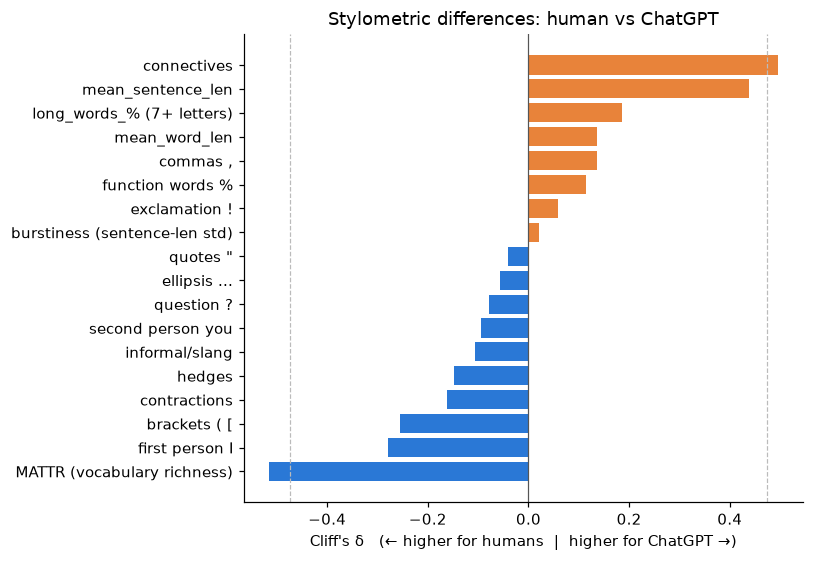

In [4]:
s = stats["Cliff's δ"].drop('n_words').sort_values()
colors = ['#2a78d6' if v < 0 else '#e8833a' for v in s]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(s.index, s.values, color=colors)
ax.axvline(0, color='#555', lw=0.8)
for x in (-0.474, 0.474): ax.axvline(x, color='#bbb', lw=0.8, ls='--')
ax.set_xlabel("Cliff's δ   (← higher for humans  |  higher for ChatGPT →)")
ax.set_title('Stylometric differences: human vs ChatGPT')
plt.tight_layout(); plt.savefig(FIG / 'fig8_stylometry_effects.png'); plt.show()

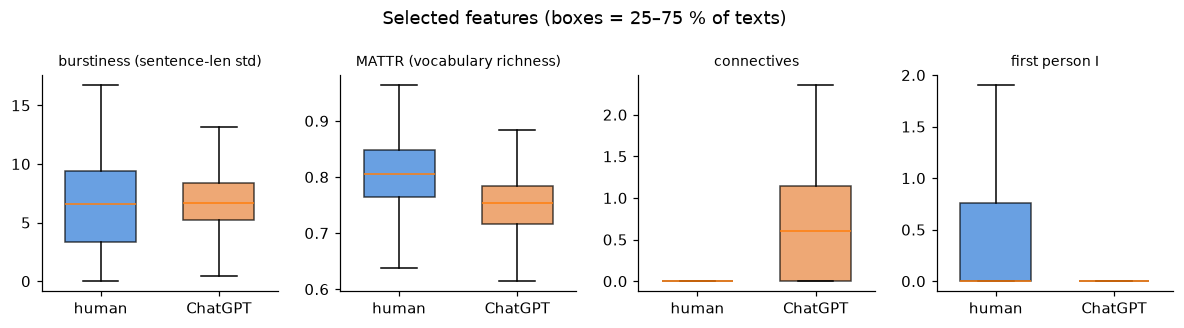

In [5]:
show = ['burstiness (sentence-len std)', 'MATTR (vocabulary richness)', 'connectives', 'first person I']
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, f in zip(axes, show):
    data = [F.loc[F.label == l, f].astype(float).values for l in ['human', 'chatgpt']]
    hi = np.percentile(np.concatenate(data), 97)
    bp = ax.boxplot([d[d <= hi] for d in data], tick_labels=['human', 'ChatGPT'], showfliers=False, patch_artist=True, widths=0.6)
    for patch, c in zip(bp['boxes'], ['#2a78d6', '#e8833a']): patch.set_facecolor(c); patch.set_alpha(0.7)
    ax.set_title(f, fontsize=9)
plt.suptitle('Selected features (boxes = 25–75 % of texts)'); plt.tight_layout()
plt.savefig(FIG / 'fig9_stylometry_boxplots.png'); plt.show()

### Robustness check: length-matched texts
Vocabulary richness and sentence statistics depend on text length, and human answers are much shorter.
We repeat the comparison only on texts of **100–300 words** (both classes in the same length range).

In [6]:
lm = F[(F.n_words >= 100) & (F.n_words <= 300)]
print('Texts in 100–300 words:', lm.label.value_counts().to_dict())
rows = []
for f in ['n_words', 'mean_sentence_len', 'burstiness (sentence-len std)', 'MATTR (vocabulary richness)',
          'connectives', 'first person I', 'brackets ( [', 'contractions', 'hedges']:
    a = lm.loc[lm.label == 'chatgpt', f].astype(float).values; b = lm.loc[lm.label == 'human', f].astype(float).values
    rows.append({'feature': f, "Cliff's δ (all texts)": stats.loc[f, "Cliff's δ"], "Cliff's δ (100–300 words)": cliffs_delta(a, b)})
length_matched = pd.DataFrame(rows).set_index('feature').round(3)
length_matched

Texts in 100–300 words: {'chatgpt': 19668, 'human': 7015}


,Cliff's δ (all texts),Cliff's δ (100–300 words)
feature,,
n_words,0.553,0.220
mean_sentence_len,0.439,0.332
burstiness (sentence-len std),0.021,-0.430
MATTR (vocabulary richness),-0.515,-0.429
connectives,0.495,0.458
first person I,-0.280,-0.394
brackets ( [,-0.255,-0.469
contractions,-0.163,-0.320
hedges,-0.147,-0.205


## 3. Stylometric detector
Two classifiers on the 18 features (length itself is excluded): **logistic regression** (standardised features,
interpretable weights) and a **random forest** (300 trees, captures non-linear interactions). Same question-level split as notebook 02.

In [7]:
RES = {}
def tpr_at_fpr(y, s, max_fpr=0.01):
    fpr, tpr, _ = roc_curve(y, s); return float(tpr[fpr <= max_fpr].max())
def evaluate(name, y, prob):
    pred = (prob >= 0.5).astype(int)
    RES[name] = {'accuracy': accuracy_score(y, pred), 'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, prob),
                 'tpr_at_1fpr': tpr_at_fpr(y, prob)}
    r = RES[name]; print(f"{name:<34} acc={r['accuracy']:.3f}  F1={r['f1']:.3f}  AUC={r['roc_auc']:.3f}  TPR@1%FPR={r['tpr_at_1fpr']:.3f}")

tr, te = F[F.split == 'train'], F[F.split == 'test']
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(tr[FEATS], tr.y)
evaluate('Stylometric features + LogReg', te.y, lr.predict_proba(te[FEATS])[:, 1])
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(tr[FEATS], tr.y)
evaluate('Stylometric features + RandomForest', te.y, rf.predict_proba(te[FEATS])[:, 1])

Stylometric features + LogReg      acc=0.854  F1=0.858  AUC=0.915  TPR@1%FPR=0.068


Stylometric features + RandomForest acc=0.918  F1=0.918  AUC=0.974  TPR@1%FPR=0.572


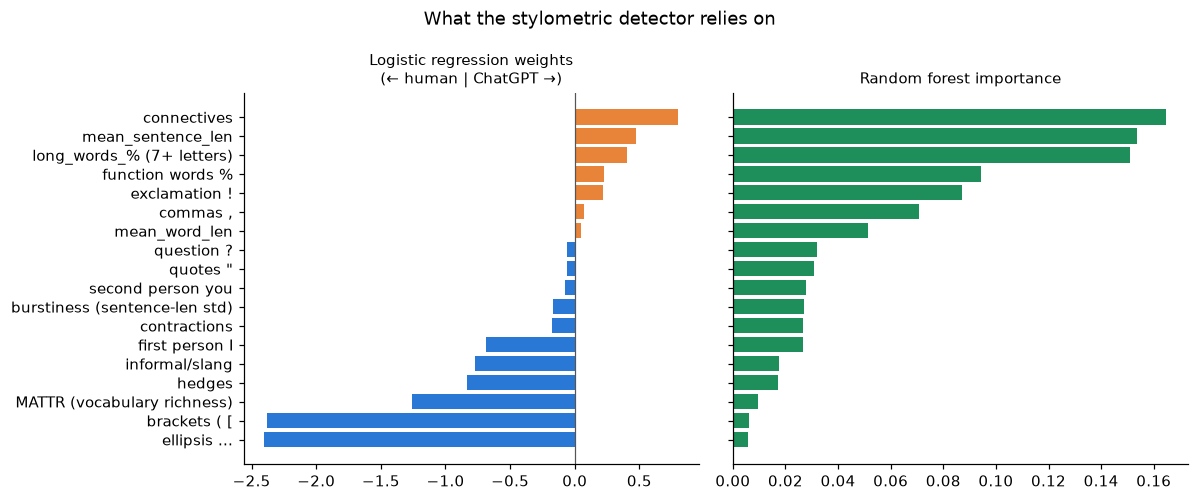

In [8]:
coef = pd.Series(lr[-1].coef_[0], index=FEATS).sort_values()
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].barh(coef.index, coef.values, color=['#2a78d6' if v < 0 else '#e8833a' for v in coef]); ax[0].axvline(0, color='#555', lw=0.8)
ax[0].set_title('Logistic regression weights\n(← human | ChatGPT →)', fontsize=10)
ax[1].barh(imp.index, imp.values, color='#1e8e5a'); ax[1].set_title('Random forest importance', fontsize=10)
ax[1].set_yticklabels([])
plt.suptitle('What the stylometric detector relies on'); plt.tight_layout()
plt.savefig(FIG / 'fig10_stylometry_importance.png'); plt.show()

## 4. Cross-domain generalisation of style features
Same leave-one-domain-out protocol as for TF-IDF in notebook 02.

In [9]:
rows = []
for d in sorted(F.domain.unique()):
    out_tr = F[(F.domain != d) & (F.split == 'train')]
    unseen = F[F.domain == d]
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED).fit(out_tr[FEATS], out_tr.y)
    in_te = te[te.domain == d]
    rows.append({'domain': d, 'F1 seen in training': f1_score(in_te.y, rf.predict(in_te[FEATS])),
                 'F1 unseen domain': f1_score(unseen.y, m.predict(unseen[FEATS]))})
lodo_style = pd.DataFrame(rows).set_index('domain').round(3)
lodo_style['drop'] = (lodo_style['F1 seen in training'] - lodo_style['F1 unseen domain']).round(3)
lodo_style

,F1 seen in training,F1 unseen domain,drop
domain,,,
finance,0.927,0.899,0.028
medicine,0.961,0.922,0.039
open_qa,0.824,0.798,0.026
reddit_eli5,0.924,0.819,0.105
wiki_csai,0.847,0.782,0.065


In [10]:
out = {'results': RES, 'cross_domain': lodo_style.reset_index().to_dict('records'),
       'feature_stats': stats.drop(columns='effect').round(4).reset_index().to_dict('records'),
       'effects': stats['effect'].astype(str).to_dict(),
       'length_matched': length_matched.reset_index().to_dict('records')}
Path('../reports/results_stylometry.json').write_text(json.dumps(out, indent=2, default=float))
print('saved reports/results_stylometry.json')

saved reports/results_stylometry.json


## 5. Interpretation
* **Confirmed (Guo et al., 2023):** ChatGPT writes longer sentences, uses many more discourse connectives
  ("additionally", "overall", "it is important") and fewer first-person, hedging, bracketed and colloquial expressions;
  humans have a richer vocabulary (higher MATTR).
* **Hidden by a confound:** *burstiness* (variation of sentence length), popularised by tools such as GPTZero, shows
  no difference over all texts (δ ≈ 0.02), because short human answers have few sentences and therefore low variation.
  On **length-matched texts (100–300 words)** humans are clearly burstier (δ ≈ −0.43). Length must be controlled
  when interpreting stylometric features.
* The other key differences survive length matching: vocabulary richness, connectives, first person and brackets
  stay medium-to-large, contractions and hedges small — so they are not an artefact of length.
* The stylometric detector is less accurate than word n-grams, but every decision is explainable by a handful of
  human-readable features — important for the ethics of accusing someone of using AI. Its random-forest version
  loses less F1 than TF-IDF on 3 of 5 unseen domains (open_qa, reddit_eli5, wiki_csai; compare with notebook 02), but its
  absolute F1 stays lower — style features transfer somewhat better, yet are not sufficient on their own.